# The asymmetric rhombus (notes Appendix B.4)

Each step follows the notes; equation labels are given in comments.

In [9]:
import sympy as sym
import circuit_quantization as cq
from circuit_quantization import Branch, Circuit, Loops, quantize, draw_circuit_diagram

sym.init_printing()
F, H, W = cq.ghz_to_farad, cq.ghz_to_henry, cq.phase_to_weber

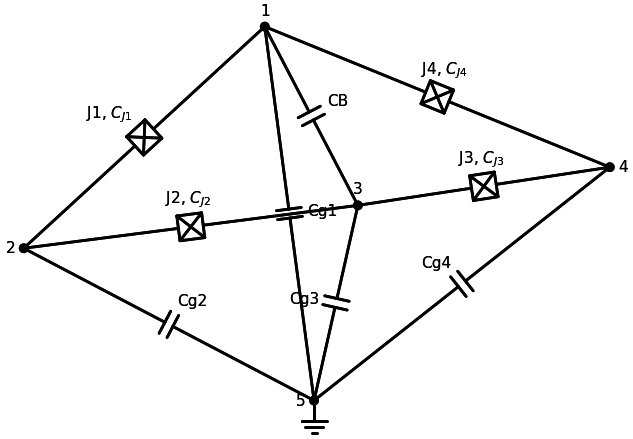

In [15]:
CJ, CB, Cg, EJ, alpha = sym.symbols("C_J C_B C_g E_J alpha", positive=True)
circuit = Circuit([
    Branch("J1", 1, 2, C=CJ, EJ=EJ),
    Branch("J2", 2, 3, C=CJ, EJ=EJ),
    Branch("J3", 3, 4, C=CJ, EJ=EJ),
    Branch("J4", 4, 1, C=CJ, EJ=alpha * EJ),
    Branch("CB", 1, 3, C=CB),
    *(Branch(f"Cg{i}", i, 5, C=Cg) for i in range(1, 5)),
], ground=5)
draw_circuit_diagram(circuit, layout="spring")

In [16]:
cycles = cq.fundamental_cycles(circuit)  # or eq:rh_G
loops = Loops(circuit, cycles, {name: 0 for name in cycles if name != "J4"})
res = quantize(circuit, loops)  # automatic basis: three compact modes, free mode removed
res

Result(circuit=Circuit(branches=(Branch(name='CB', tail=1, head=3, C=C_B, L=None, EJ=None, V=None), Branch(name='Cg1', tail=1, head=5, C=C_g, L=None, EJ=None, V=None), Branch(name='Cg2', tail=2, head=5, C=C_g, L=None, EJ=None, V=None), Branch(name='Cg3', tail=3, head=5, C=C_g, L=None, EJ=None, V=None), Branch(name='Cg4', tail=4, head=5, C=C_g, L=None, EJ=None, V=None), Branch(name='J1', tail=1, head=2, C=C_J, L=None, EJ=E_J, V=None), Branch(name='J2', tail=2, head=3, C=C_J, L=None, EJ=E_J, V=None), Branch(name='J3', tail=3, head=4, C=C_J, L=None, EJ=E_J, V=None), Branch(name='J4', tail=4, head=1, C=C_J, L=None, EJ=E_J*alpha, V=None)), ground=5, t=t), loops=<circuit_quantization.circuit.Loops object at 0x12f958690>, lag=Lagrangian(Omega=Matrix([
[ 1,  1,  0,  0,  0,  1,  0,  0, -1],
[ 0,  0,  1,  0,  0, -1,  1,  0,  0],
[-1,  0,  0,  1,  0,  0, -1,  1,  0],
[ 0,  0,  0,  0,  1,  0,  0, -1,  1],
[ 0, -1, -1, -1, -1,  0,  0,  0,  0]]), Omega_int=Matrix([
[ 1, 1, 0, 0, 0,  1,  0,  0, -1],


In [6]:
res.coords.types

('c', 'c', 'c')

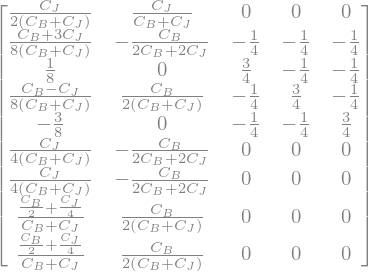

In [7]:
res.B.subs(Cg, 0).applyfunc(sym.simplify)